План Kaggle-проекта (House Prices — Regression)

# Этап 1 — Setup и понимание задачи

Цель проекта: предсказать стоимость дома (SalePrice)

Метрика: RMSE на log-transform (RMSE(log(SalePrice)))

Структура проекта: папки data/raw, data/processed, notebooks, src, submissions

Загрузка данных: train.csv, test.csv + первичная проверка размеров и наличия целевой переменной

In [201]:
# ===============================
# 0️⃣ Подготовка
#  - Импорт библиотек
#  - Определение путей к данным
#  - Загрузка train/test
#  - Быстрый просмотр данных
# ===============================
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw")

train = pd.read_csv(DATA_PATH / "train.csv")
test  = pd.read_csv(DATA_PATH / "test.csv")

print("Размер train:", train.shape)
print("Размер test:", test.shape)
print("\nПервые 5 строк train:")
print(train.head())


Размер train: (1460, 81)
Размер test: (1459, 80)

Первые 5 строк train:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12 

In [202]:
# ===============================
# 1️⃣ Проверка наличия Target
#  - Проверяем, что SalePrice есть в train
#  - Проверяем, что SalePrice отсутствует в test
# ===============================
target = "SalePrice"
print("\nSalePrice в train (True):", target in train.columns)
print("SalePrice в test (False):", target in test.columns)



SalePrice в train (True): True
SalePrice в test (False): False


In [208]:
# ===============================
# 2️⃣ Структура данных: сравнение train и test

#  - Признаки без target

#  - Совпадение имен признаков
#  - Совпадение типов данных
# ===============================
train_features = train.drop(columns=target).columns
test_features  = test.columns

features_match = all(train_features == test_features)
print("\nПризнаки train/test совпадают (True):", features_match)

train_types = train[train_features].dtypes
test_types  = test[test_features].dtypes
types_match = all(train_types == test_types)
print("Типы данных совпадают (True):", types_match)



Признаки train/test совпадают (True): True
Типы данных совпадают (True): True


In [209]:
# 2.1 
# Типы данных совпадают: False

# Находим общие колонки
common_cols = train.columns.intersection(test.columns)

# Фильтруем dtypes только по этим колонкам
train_types = train[common_cols].dtypes
test_types = test[common_cols].dtypes

# Сравниваем типы
diff_types = train_types != test_types

# Колонки с разными типами
cols_with_type_diff = common_cols[diff_types].tolist()

# Вывод
print("Колонки с разными типами данных:")
for col in cols_with_type_diff:
    print(f"{col}: train={train[col].dtype}, test={test[col].dtype}")

# Список колонок для дальнейшей обработки
print("\nСписок колонок для обработки:")
print(cols_with_type_diff)


Колонки с разными типами данных:

Список колонок для обработки:
[]


In [207]:
# ===============================
# 2.2 fix_dtype_mismatch_train_test
# ===============================

cols_to_convert = ['BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF',
                   'BsmtFullBath','BsmtHalfBath','GarageCars','GarageArea']

# Типы до преобразования
print("Типы данных до преобразования:")
df_before = pd.DataFrame({
    'train': train[cols_to_convert].dtypes.astype(str),
    'test': test[cols_to_convert].dtypes.astype(str)
})
print(df_before)

# Приведение к float64
train[cols_to_convert] = train[cols_to_convert].astype('float64')
test[cols_to_convert] = test[cols_to_convert].astype('float64')

# Типы после преобразования
print("\nТипы данных после преобразования к float64:")
df_after = pd.DataFrame({
    'train': train[cols_to_convert].dtypes.astype(str),
    'test': test[cols_to_convert].dtypes.astype(str)
})
print(df_after)



Типы данных до преобразования:
              train     test
BsmtFinSF1    int64  float64
BsmtFinSF2    int64  float64
BsmtUnfSF     int64  float64
TotalBsmtSF   int64  float64
BsmtFullBath  int64  float64
BsmtHalfBath  int64  float64
GarageCars    int64  float64
GarageArea    int64  float64

Типы данных после преобразования к float64:
                train     test
BsmtFinSF1    float64  float64
BsmtFinSF2    float64  float64
BsmtUnfSF     float64  float64
TotalBsmtSF   float64  float64
BsmtFullBath  float64  float64
BsmtHalfBath  float64  float64
GarageCars    float64  float64
GarageArea    float64  float64


In [210]:
# ===============================
# 3️⃣ Быстрая статистика Target
#  - Минимум, максимум
#  - Среднее и медиана
#  - Общая информация для понимания диапазона
# ===============================
print("\nСтатистика SalePrice:")
print(train[target].describe())

min_price = train[target].min()
max_price = train[target].max()
mean_price = train[target].mean()
median_price = train[target].median()
print(f"\nДиапазон: {min_price} — {max_price}")
print(f"Среднее: {mean_price}, Медиана: {median_price}")



Статистика SalePrice:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Диапазон: 34900 — 755000
Среднее: 180921.19589041095, Медиана: 163000.0


In [212]:
# ===============================
# 4️⃣ Проверка пропусков
#  - Считаем пропуски в каждом столбце
#  - Выводим топ-5 признаков с пропусками
# ===============================
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Пропуски:\n", missing.head(5))


Пропуски:
 PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
dtype: int64


In [213]:
# ===============================
# 5️⃣ Итоговые выводы ЭТАП 1
#  - Target есть только в train
#  - Признаки train/test совпадают
#  - Типы данных совпадают
#  - Диапазон SalePrice понятен
#  - Пропуски выявлены и требуют обработки
# ===============================
print("ЭТАП 1 завершён. Данные готовы для ЭТАП 2 — глубокого EDA.")


ЭТАП 1 завершён. Данные готовы для ЭТАП 2 — глубокого EDA.


# Этап 1.1 — Проверки чистоты данных на Этапе 1

In [216]:
# Повторяющиеся строки

# Считаем дубликаты
duplicate_rows = train.duplicated().sum()
print(f"Количество дубликатов в train: {duplicate_rows}")
duplicate_rows = test.duplicated().sum()
print(f"Количество дубликатов в test: {duplicate_rows}")

Количество дубликатов в train: 0
Количество дубликатов в test: 0


In [218]:
# Проверяем, уникальны ли Id
print(f"Уникальные Id в train: {train['Id'].nunique()}, всего строк: {len(train)}")
print(f"Уникальные Id в test: {test['Id'].nunique()}, всего строк: {len(test)}")


Уникальные Id в train: 1460, всего строк: 1460
Уникальные Id в test: 1459, всего строк: 1459


In [219]:
# Неожиданные отрицательные или нулевые значения Для признаков, где они не допускаются

num_cols = train.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    neg_vals = (train[col] < 0).sum()
    zero_vals = (train[col] == 0).sum()
    if neg_vals > 0 or zero_vals > 0:
        print(f"{col}: отрицательные={neg_vals}, нули={zero_vals}")


MasVnrArea: отрицательные=0, нули=861
BsmtFinSF1: отрицательные=0, нули=467
BsmtFinSF2: отрицательные=0, нули=1293
BsmtUnfSF: отрицательные=0, нули=118
TotalBsmtSF: отрицательные=0, нули=37
2ndFlrSF: отрицательные=0, нули=829
LowQualFinSF: отрицательные=0, нули=1434
BsmtFullBath: отрицательные=0, нули=856
BsmtHalfBath: отрицательные=0, нули=1378
FullBath: отрицательные=0, нули=9
HalfBath: отрицательные=0, нули=913
BedroomAbvGr: отрицательные=0, нули=6
KitchenAbvGr: отрицательные=0, нули=1
Fireplaces: отрицательные=0, нули=690
GarageCars: отрицательные=0, нули=81
GarageArea: отрицательные=0, нули=81
WoodDeckSF: отрицательные=0, нули=761
OpenPorchSF: отрицательные=0, нули=656
EnclosedPorch: отрицательные=0, нули=1252
3SsnPorch: отрицательные=0, нули=1436
ScreenPorch: отрицательные=0, нули=1344
PoolArea: отрицательные=0, нули=1453
MiscVal: отрицательные=0, нули=1408


In [220]:
# Повторяющиеся комбинации признаков. 
# Иногда полезно проверить уникальные сочетания важных категориальных признаков, чтобы увидеть дубликаты объектов по сути:

print(train[['Neighborhood','HouseStyle','SaleCondition']].duplicated().sum())


1272


# ЭТАП 2 — Глубокий EDA (Exploratory Data Analysis)

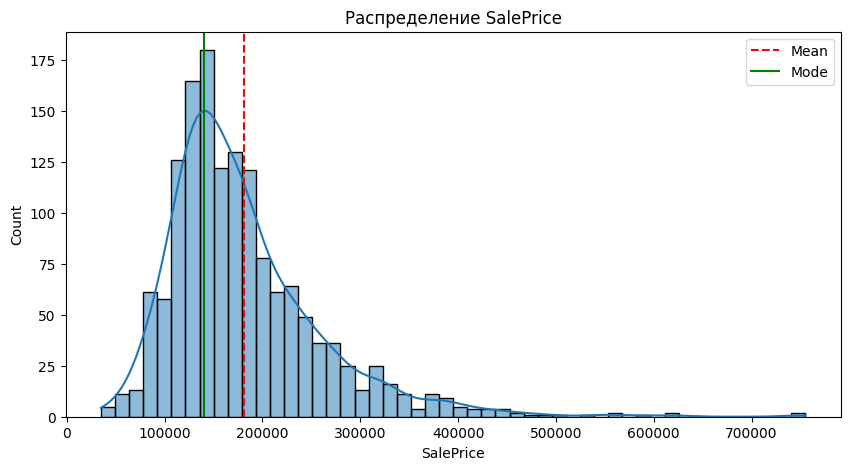

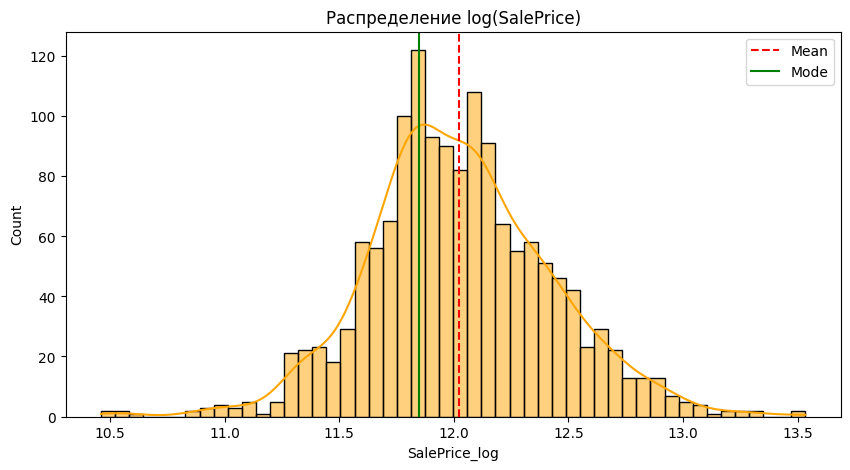

Skew до трансформации: 1.8828757597682129
Skew после log1p: 0.12134661989685333


In [224]:
# ===============================
# 2️⃣1 Анализ Target — SalePrice с mean и mode
# ===============================
plt.figure(figsize=(10,5))
sns.histplot(train['SalePrice'], bins=50, kde=True)
plt.axvline(train['SalePrice'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(train['SalePrice'].mode()[0], color='green', linestyle='-', label='Mode')
plt.title('Распределение SalePrice')
plt.legend()
plt.show()

# лог-трансформация
train['SalePrice_log'] = np.log1p(train['SalePrice'])

plt.figure(figsize=(10,5))
sns.histplot(train['SalePrice_log'], bins=50, kde=True, color='orange')
plt.axvline(train['SalePrice_log'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(train['SalePrice_log'].mode()[0], color='green', linestyle='-', label='Mode')
plt.title('Распределение log(SalePrice)')
plt.legend()
plt.show()

print("Skew до трансформации:", train['SalePrice'].skew())
print("Skew после log1p:", train['SalePrice_log'].skew())


In [228]:
# ===============================
# 2️⃣2 Быстрая статистика Target
#  - Мин, макс, среднее, медиана
#  - Основные квантили
# ===============================
print(train['SalePrice'].describe())
print("\nМедиана:", train['SalePrice'].median())
print("Среднее:", train['SalePrice'].mean())
print("Диапазон:", train['SalePrice'].min(), "-", train['SalePrice'].max())


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Медиана: 163000.0
Среднее: 180921.19589041095
Диапазон: 34900 - 755000


In [229]:
# ===============================
# 2️⃣3 Анализ категориальных признаков 
# 
# 
#  2.3.1 Table - первые 5 и последние 5 + количество каждого
# ===============================
pd.set_option('display.max_colwidth', None)  # показывать полностью

cat_cols = train.select_dtypes(include='object').columns
cat_summary = []

for col in cat_cols:
    counts = train[col].fillna('NaN').value_counts()  # количество каждого уникального значения
    uniques = counts.index.tolist()
    n_uniques = len(uniques)
    
    # безопасная сортировка
    uniques_sorted = sorted(uniques, key=lambda x: str(x))
    
    # формируем строку с уникальными значениями
    if n_uniques <= 10:
        uniques_str = ', '.join(map(str, uniques_sorted))
        counts_str = ', '.join(map(str, [counts[u] for u in uniques_sorted]))
    else:
        first5 = ', '.join(map(str, uniques_sorted[:5]))
        last5  = ', '.join(map(str, uniques_sorted[-5:]))
        uniques_str = f"{first5} ... {last5}"
        counts_str = ', '.join(map(str, [counts[u] for u in uniques_sorted[:5]])) + " ... " + \
                     ', '.join(map(str, [counts[u] for u in uniques_sorted[-5:]]))
    
    # добавляем в список
    cat_summary.append({
        'Признак': col,
        'Уникальных значений': n_uniques,
        'Примеры уникальных значений': uniques_str,
        'Количество каждого уникального значения': counts_str
    })

# создаём DataFrame и сортируем по количеству уникальных значений (по убыванию)
cat_summary_df = pd.DataFrame(cat_summary)
cat_summary_df = cat_summary_df.sort_values(by='Уникальных значений', ascending=False)
cat_summary_df.reset_index(drop=True, inplace=True)

# выводим таблицу
cat_summary_df


,Признак,Уникальных значений,Примеры уникальных значений,Количество каждого уникального значения
0,Neighborhood,25,"Blmngtn, Blueste, BrDale, BrkSide, ClearCr ... SawyerW, Somerst, StoneBr, Timber, Veenker","17, 2, 16, 58, 28 ... 59, 86, 25, 38, 11"
1,Exterior2nd,16,"AsbShng, AsphShn, Brk Cmn, BrkFace, CBlock ... Stone, Stucco, VinylSd, Wd Sdng, Wd Shng","20, 3, 7, 25, 1 ... 5, 26, 504, 197, 38"
2,Exterior1st,15,"AsbShng, AsphShn, BrkComm, BrkFace, CBlock ... Stone, Stucco, VinylSd, Wd Sdng, WdShing","20, 1, 2, 50, 1 ... 2, 25, 515, 206, 26"
3,Condition1,9,"Artery, Feedr, Norm, PosA, PosN, RRAe, RRAn, RRNe, RRNn","48, 81, 1260, 8, 19, 11, 26, 2, 5"
4,SaleType,9,"COD, CWD, Con, ConLD, ConLI, ConLw, New, Oth, WD","43, 4, 2, 9, 5, 5, 122, 3, 1267"
5,HouseStyle,8,"1.5Fin, 1.5Unf, 1Story, 2.5Fin, 2.5Unf, 2Story, SFoyer, SLvl","154, 14, 726, 8, 11, 445, 37, 65"
6,RoofMatl,8,"ClyTile, CompShg, Membran, Metal, Roll, Tar&Grv, WdShake, WdShngl","1, 1434, 1, 1, 1, 11, 5, 6"
7,Condition2,8,"Artery, Feedr, Norm, PosA, PosN, RRAe, RRAn, RRNn","2, 6, 1445, 1, 2, 1, 1, 2"
8,BsmtFinType2,7,"ALQ, BLQ, GLQ, LwQ, NaN, Rec, Unf","19, 33, 14, 46, 38, 54, 1256"
9,BsmtFinType1,7,"ALQ, BLQ, GLQ, LwQ, NaN, Rec, Unf","220, 148, 418, 74, 37, 133, 430"


In [235]:
# 2.3.2. Extra 
# ===============================
#  2.3.2. Extra  Tanles
# ===============================
cat_cols = train.select_dtypes(include=['object']).columns
print(f"Категориальные признаки: {len(cat_cols)}")

# Топ-5 самых часто встречающихся категорий для каждой колонки
for col in cat_cols:
    print(f"\nКолонка: {col}")
    print(train[col].value_counts().head(5))

Категориальные признаки: 43

Колонка: MSZoning
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Колонка: Street
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Колонка: Alley
Alley
Grvl    50
Pave    41
Name: count, dtype: int64

Колонка: LotShape
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

Колонка: LandContour
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

Колонка: Utilities
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

Колонка: LotConfig
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

Колонка: LandSlope
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Колонка: Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Name: count, dtype: int64

Колонка: Condition1
Condition1
Nor

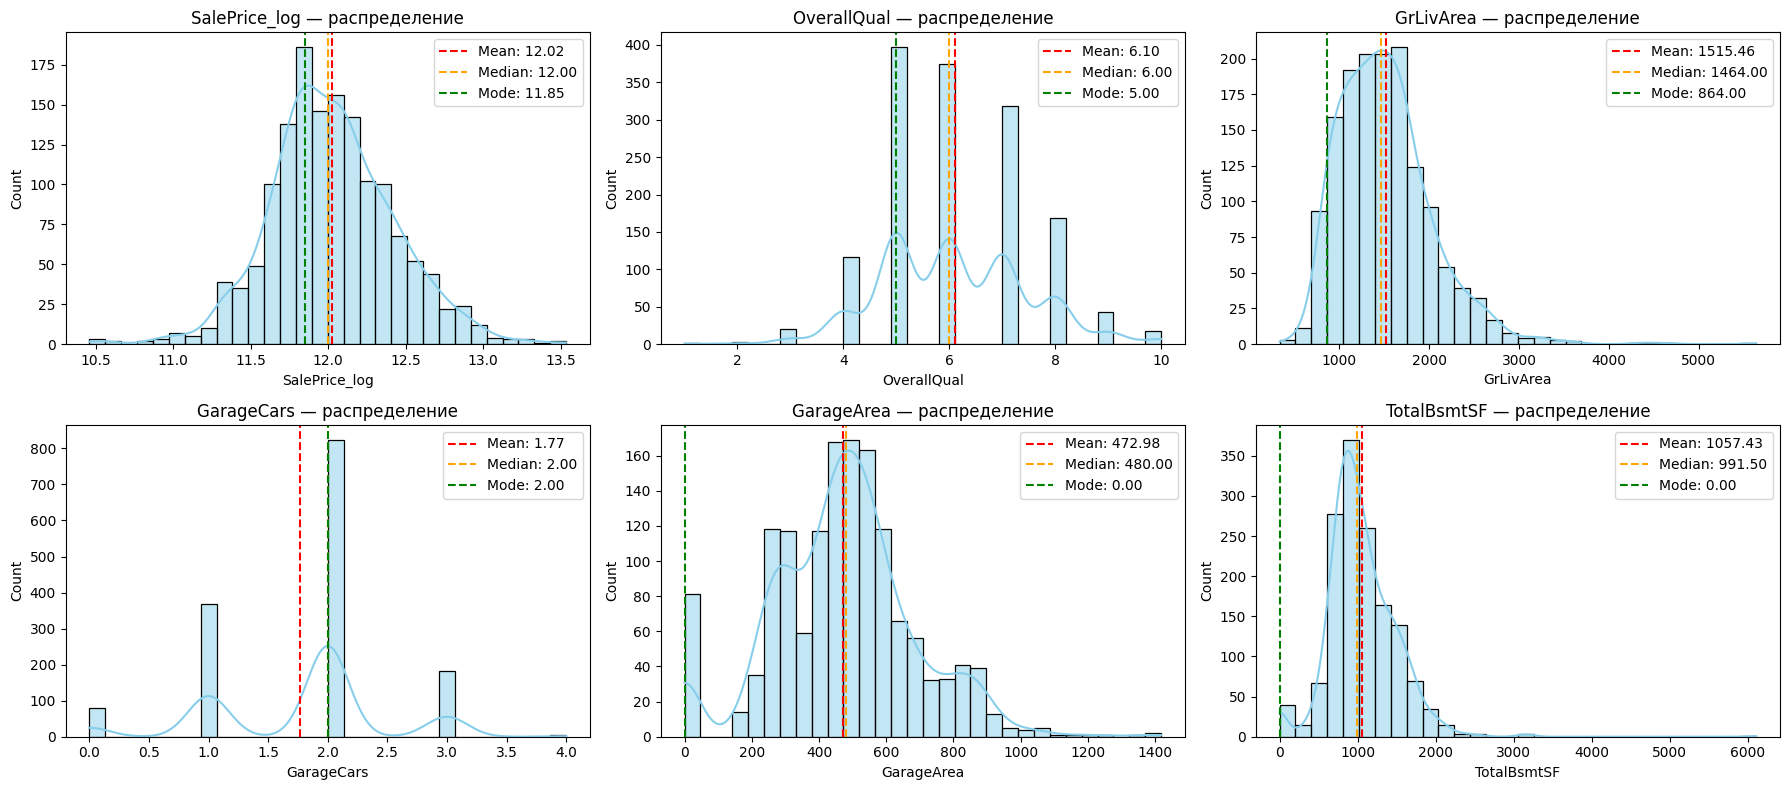

In [230]:
# ===============================
# 2.4.1 Анализ распределения топ-числовых признаков
#  - Построение гистограмм с KDE
#  - Отображение Mean, Median и Mode
# ===============================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ===== Топ числовые признаки по корреляции с таргетом =====
num_cols = train.select_dtypes(include=['float64','int64']).columns.drop('SalePrice')
corr = train[num_cols].corrwith(train['SalePrice']).sort_values(ascending=False)
top_num_cols = corr.head(6).index  # Например, 6 топ признаков

# ===== Фигура с subplots =====
n_cols = 3  # количество графиков в строке
n_rows = (len(top_num_cols) + n_cols - 1) // n_cols  # вычисляем количество рядов
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()  # для удобного итератора

for i, col in enumerate(top_num_cols):
    ax = axes[i]
    
    mean_val = train[col].mean()
    median_val = train[col].median()
    mode_val = train[col].mode().iloc[0] if train[col].nunique() > 1 else None
    
    # Histogram + KDE
    sns.histplot(train[col], kde=True, bins=30, color='skyblue', ax=ax)
    
    # Линии статистик
    ax.axvline(mean_val, color='red', linestyle='--')
    ax.axvline(median_val, color='orange', linestyle='--')
    if mode_val is not None:
        ax.axvline(mode_val, color='green', linestyle='--')
    
    # Легенда
    legend_labels = [f"Mean: {mean_val:.2f}", f"Median: {median_val:.2f}"]
    legend_colors = ['red', 'orange']
    if mode_val is not None:
        legend_labels.append(f"Mode: {mode_val:.2f}")
        legend_colors.append('green')
    
    handles = [plt.Line2D([0], [0], color=c, linestyle='--') for c in legend_colors]
    ax.legend(handles, legend_labels, loc='upper right', frameon=True)
    ax.set_title(f'{col} — распределение')

# Скрываем пустые подграфики, если есть
for j in range(len(top_num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



Корреляция с SalePrice (топ 10):
SalePrice_log    0.948374
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
dtype: float64


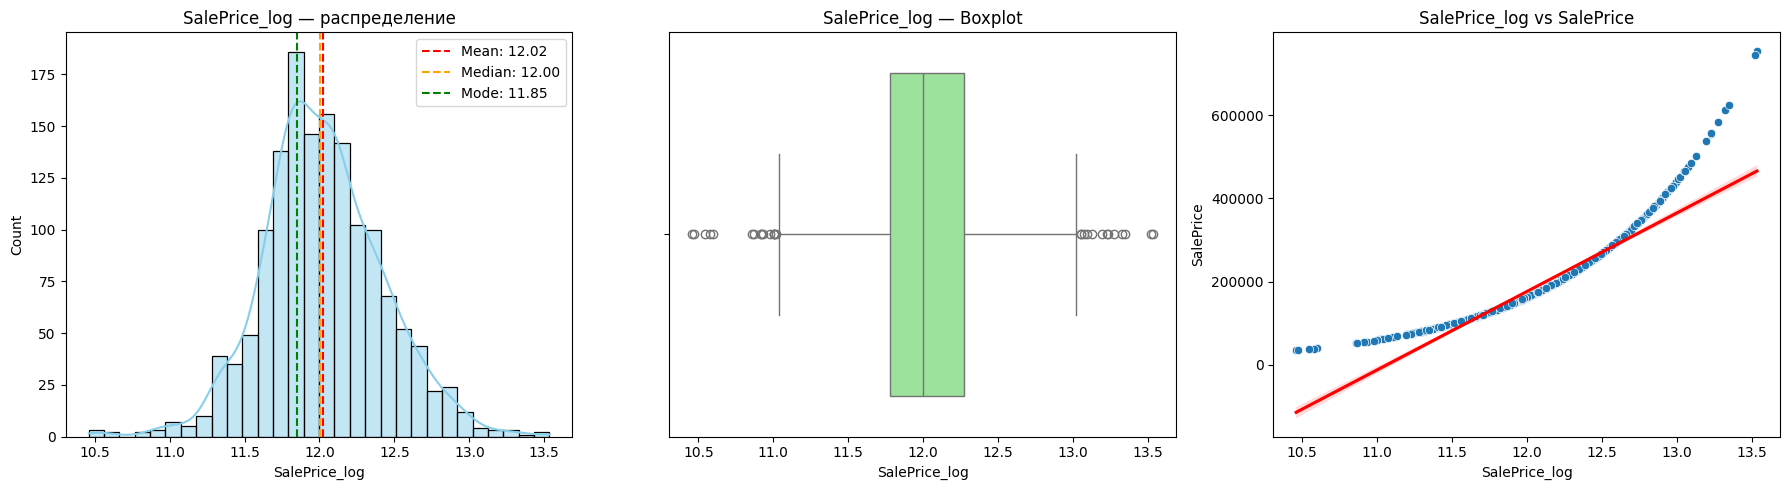

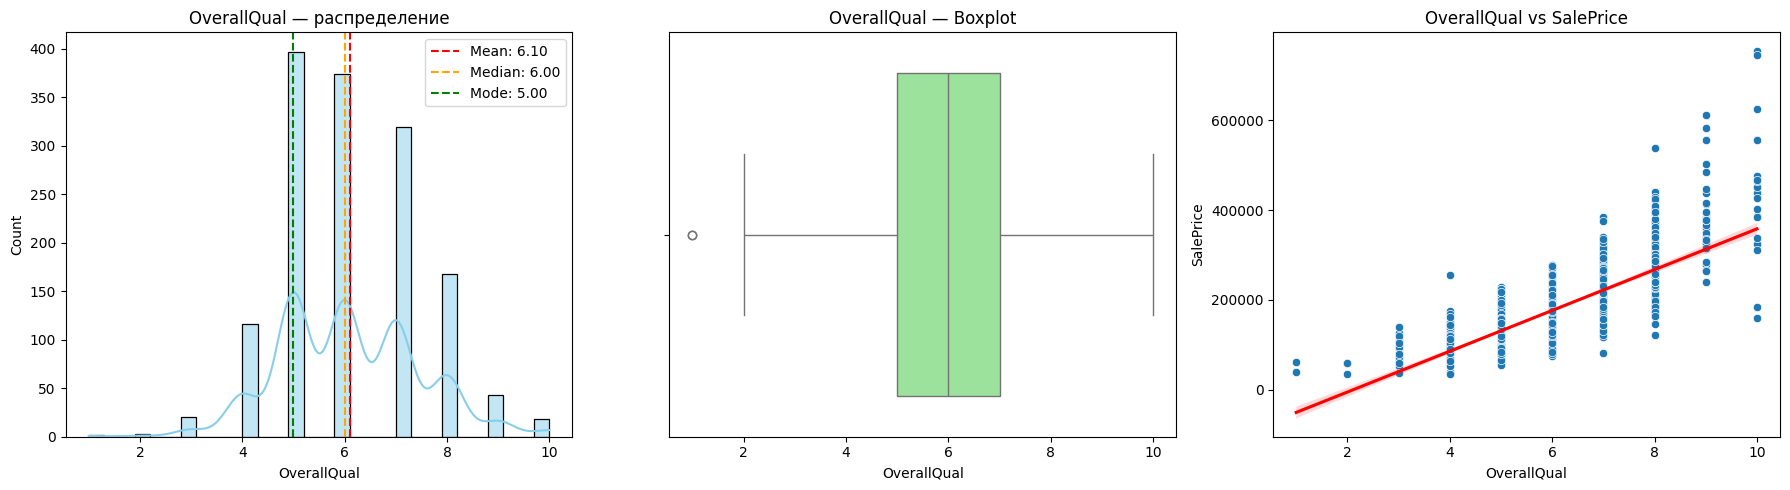

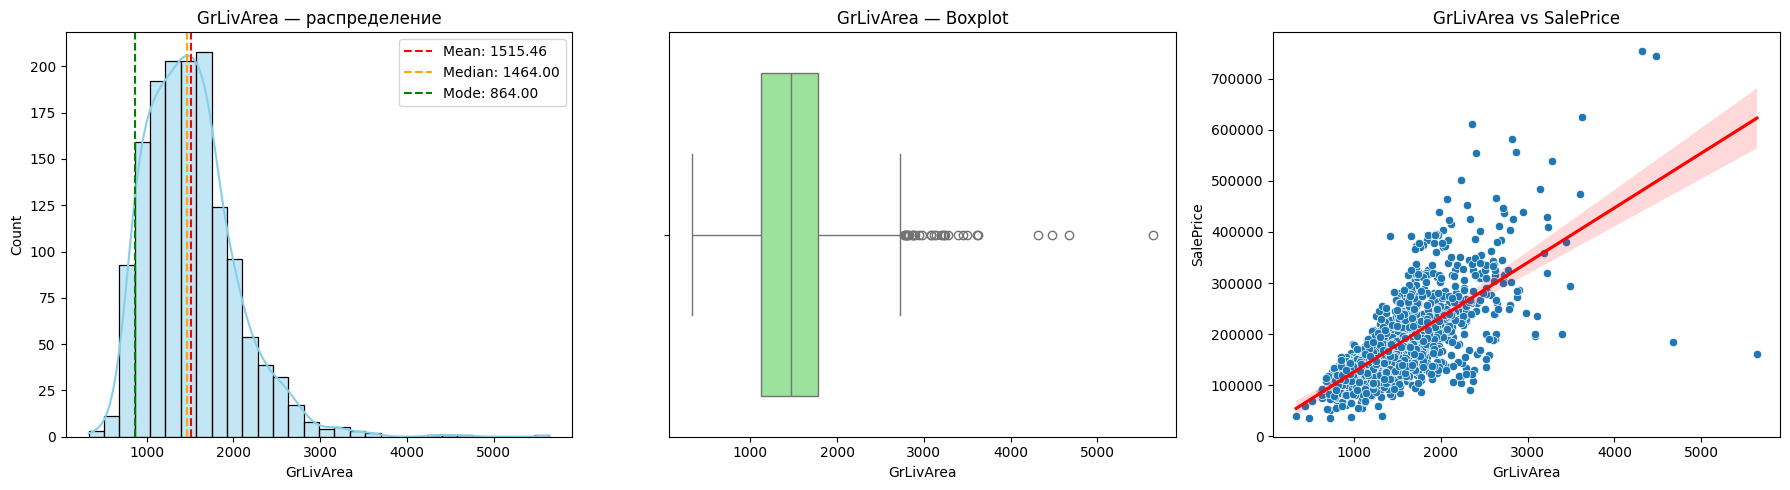

In [231]:
# ===============================
# 2️⃣4.2 Анализ числовых признаков
#  - Распределение
#  - Корреляция с таргетом
# ===============================
num_cols = train.select_dtypes(include=['float64','int64']).columns.drop('SalePrice')
corr = train[num_cols].corrwith(train['SalePrice']).sort_values(ascending=False)
print("\nКорреляция с SalePrice (топ 10):")
print(corr.head(10))

import matplotlib.pyplot as plt
import seaborn as sns

top_num_cols = corr.head(3).index

for col in top_num_cols:
    plt.figure(figsize=(18,5))
    
    # Рассчёт статистик
    mean_val = train[col].mean()
    median_val = train[col].median()
    if train[col].nunique() > 1:
        mode_val = train[col].mode().iloc[0]
    else:
        mode_val = None
    
    # 1. Histogram + KDE + линии статистик
    plt.subplot(1,3,1)
    sns.histplot(train[col], kde=True, bins=30, color='skyblue')
    
    # Линии статистик
    plt.axvline(mean_val, color='red', linestyle='--', label='Mean')
    plt.axvline(median_val, color='orange', linestyle='--', label='Median')
    if mode_val is not None:
        plt.axvline(mode_val, color='green', linestyle='--', label='Mode')
    
    # Подписи рядом с легендой
    legend_labels = [f"Mean: {mean_val:.2f}", f"Median: {median_val:.2f}"]
    legend_colors = ['red', 'orange']
    if mode_val is not None:
        legend_labels.append(f"Mode: {mode_val:.2f}")
        legend_colors.append('green')
    
    # Добавляем подписи как отдельные элементы рядом с легендой
    handles = [plt.Line2D([0], [0], color=c, linestyle='--') for c in legend_colors]
    plt.legend(handles, legend_labels, loc='upper right', frameon=True)
    
    plt.title(f'{col} — распределение')
    
    # 2. Boxplot
    plt.subplot(1,3,2)
    sns.boxplot(x=train[col], color='lightgreen')
    plt.title(f'{col} — Boxplot')
    
    # 3. Scatterplot с таргетом
    plt.subplot(1,3,3)
    sns.scatterplot(x=train[col], y=train['SalePrice'])
    sns.regplot(x=train[col], y=train['SalePrice'], scatter=False, color='red')
    plt.title(f'{col} vs SalePrice')
    
    plt.tight_layout()
    plt.show()



Топ-10 числовых признаков по корреляции с таргетом:
SalePrice_log    0.948374
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
dtype: float64


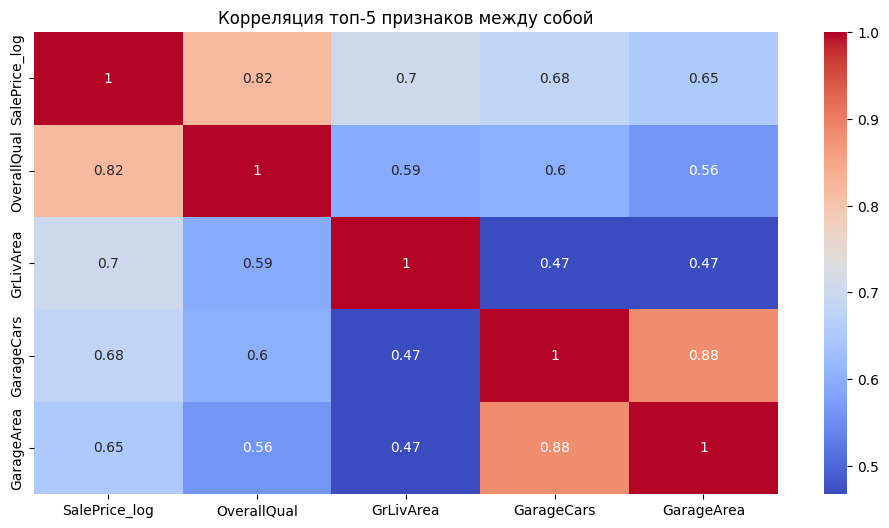

In [236]:
# ===============================
# 2.4.3 Анализ числовых признаков
# ===============================
num_cols = train.select_dtypes(include=['int64', 'float64']).columns.drop(target)

# Корреляция с таргетом
corr_target = train[num_cols].corrwith(train[target]).sort_values(ascending=False)
print("\nТоп-10 числовых признаков по корреляции с таргетом:")
print(corr_target.head(10))

# Визуализация корреляции топ-5 признаков
top5_corr = corr_target.head(5).index
plt.figure(figsize=(12,6))
sns.heatmap(train[top5_corr].corr(), annot=True, cmap='coolwarm')
plt.title("Корреляция топ-5 признаков между собой")
plt.show()

In [232]:
# ===============================
# 2️⃣5 Проверка пропусков (детально)
#  - Сколько пропусков
#  - Какие признаки требуют обработки
# ===============================
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Пропуски в train:\n", missing)

missing_test = test.isnull().sum()
missing_test = missing_test[missing_test > 0].sort_values(ascending=False)
print("\nПропуски в test:\n", missing_test)


Пропуски в train:
 PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Пропуски в test:
 PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageQual        78
GarageCond        78
GarageYrBlt       78
GarageFinish      78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
Functional         2
BsmtFullBath       2
Utilities          2
BsmtHalfBath       2
Exterior1st        1
Exterior2nd        1
TotalBsmtSF        1
Bsmt

In [237]:
# ===============================
# 2️⃣6.1 Выводы ЭТАП 2
#  - Target сильно skewed → использовать log
#  - Есть категориальные признаки с редкими значениями → можно объединять
#  - Есть пропуски → будут заполняться позже (Feature Engineering)
#  - Часть числовых признаков сильно коррелирует с таргетом → кандидаты для модели
# ===============================

# ===============================
#  2.6.2 Гипотезы и выводы
# ===============================
# - Признаки с высокой корреляцией с SalePrice (например, GrLivArea, OverallQual) считаем ключевыми
# - Целевой признак логарифмирован для стабилизации дисперсии
# - Категориальные признаки требуют обработки пропусков и кодирования
# - Необычные выбросы можно выявить визуально (например, по GrLivArea и SalePrice)
# - В дальнейшем можно создавать новые признаки (Feature Engineering) на основе взаимодействий

print("ЭТАП 2 завершён. Данные изучены, готовы к Feature Engineering (ЭТАП 4).")


ЭТАП 2 завершён. Данные изучены, готовы к Feature Engineering (ЭТАП 4).


# ЭТАП 3 — Baseline модель (Linear Regression)

In [243]:
# ============================================================
# ЭТАП 3️⃣ — BASELINE МОДЕЛЬ (Linear Regression)
# ============================================================
# Цель этапа:
#  - получить быструю и понятную точку отсчёта
#  - проверить корректность данных
#  - убедиться, что утечек таргета нет
#  - зафиксировать reference-метрику RMSE
#
# Модель:
#  - LinearRegression (без тюнинга)
#
# Метрика:
#  - RMSE по log(SalePrice)
#
# ВАЖНО:
#  - baseline НЕ оптимизируется
#  - используется ТОЛЬКО как reference
# ============================================================

import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# ============================================================
# 3️⃣1 Подготовка данных
# ============================================================

# лог-трансформация таргета (стандарт для House Prices)
y = np.log1p(train['SalePrice'])

# признаки: удаляем target и Id
X = train.drop(columns=['SalePrice', 'Id'])

# защита от утечки: удаляем колонки, полностью дублирующие таргет
dup_target_cols = [col for col in X.columns if (X[col] == y).all()]
if dup_target_cols:
    print("⚠️ Удалены колонки, дублирующие таргет:", dup_target_cols)
    X = X.drop(columns=dup_target_cols)

# разделяем признаки по типам
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print(f"Числовые признаки: {len(num_cols)}")
print(f"Категориальные признаки: {len(cat_cols)}")

# ============================================================
# 3️⃣2 Preprocessing + модель
# ============================================================

# числовые признаки:
#  - заполняем NaN медианой
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# категориальные признаки:
#  - заполняем NaN самым частым значением
#  - OneHotEncoding
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# объединяем трансформации
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# итоговый pipeline
pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', LinearRegression())
])

# ============================================================
# 3️⃣3 Cross-Validation
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    rmse_scores.append(rmse)

    print(f"Fold {fold}: RMSE = {rmse:.4f}")

BASELINE_RMSE = np.mean(rmse_scores)

# ============================================================
# 3️⃣4 Фиксация результата
# ============================================================

print("=" * 60)
print("✅ ЭТАП 3 ЗАВЕРШЁН — BASELINE МОДЕЛЬ")
print("-" * 60)
print("Модель: LinearRegression")
print("Метрика: RMSE (log(SalePrice))")
print("Cross-Validation: 5-Fold KFold")
print(f"\n📌 BASELINE RMSE = {BASELINE_RMSE:.4f}")
print("=" * 60)

# ============================================================
# 3️⃣5 Интерпретация (важно для проекта)
# ============================================================

# - RMSE ~0.15 — адекватный baseline для House Prices
# - Данные информативны
# - Утечки таргета отсутствуют
# - Есть потенциал для улучшения через:
#     • регуляризацию (Ridge)
#     • нелинейность (RandomForest)
#     • бустинг (LightGBM, CatBoost)
#
# BASELINE_RMSE — reference.
# Любая следующая модель ОБЯЗАНА быть лучше этого значения.
#
# ЭТАП 3 ЗАКРЫТ.
# ============================================================


⚠️ Удалены колонки, дублирующие таргет: ['SalePrice_log']
Числовые признаки: 36
Категориальные признаки: 43
Fold 1: RMSE = 0.1281
Fold 2: RMSE = 0.1246
Fold 3: RMSE = 0.2426
Fold 4: RMSE = 0.1552
Fold 5: RMSE = 0.1132
✅ ЭТАП 3 ЗАВЕРШЁН — BASELINE МОДЕЛЬ
------------------------------------------------------------
Модель: LinearRegression
Метрика: RMSE (log(SalePrice))
Cross-Validation: 5-Fold KFold

📌 BASELINE RMSE = 0.1527


 # ЭТАП 4 — Feature Engineering & Улучшенные модели

Числовые признаки: 36
Категориальные признаки: 43
Ridge: Средний RMSE = 0.1486
RandomForest: Средний RMSE = 0.1458
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001915 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658


c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001294 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898


c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000854 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3185
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 177
[LightGBM] [Info] Start training from score 12.022759


c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (2 outputs left out)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000725 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3201
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 176
[LightGBM] [Info] Start training from score 12.022040


c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LGBM: Средний RMSE = 0.1349
XGBoost: Средний RMSE = 0.1407
CatBoost: Средний RMSE = 0.1274

Сравнение моделей по RMSE:
          Model      RMSE
0      CatBoost  0.127368
1          LGBM  0.134921
2       XGBoost  0.140678
3  RandomForest  0.145802
4         Ridge  0.148554


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_19024\2053130565.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='RMSE', data=results_df, palette='viridis')


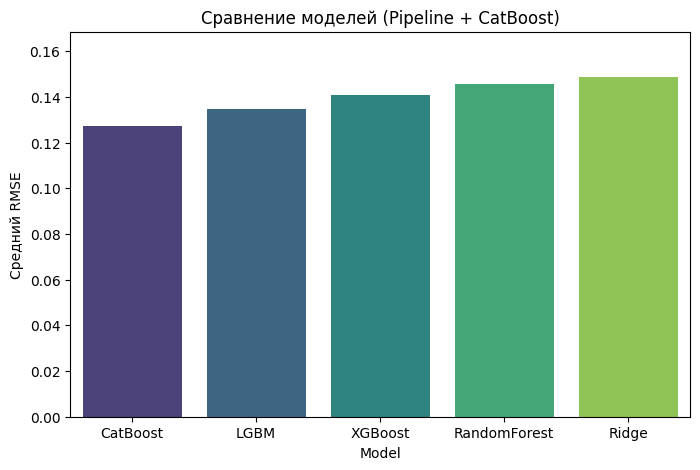

In [257]:
# ===============================
# 4️⃣ ЭТАП 4 — Feature Engineering & Baseline для моделей
# ===============================

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# 4.1 ЕДИНАЯ подготовка данных
# ===============================

y = np.log1p(train['SalePrice'])
X = train.drop(columns=['SalePrice', 'Id', 'SalePrice_log'], errors='ignore')

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print(f"Числовые признаки: {len(num_cols)}")
print(f"Категориальные признаки: {len(cat_cols)}")

# ===============================
# 4.2 Preprocessing Pipeline (кроме CatBoost)
# ===============================

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ===============================
# 4.3 Список моделей
# ===============================

models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
}

# ===============================
# 4.4 Cross-Validation (Pipeline)
# ===============================

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocess', preprocessor),
        ('model', model)
    ])
    
    rmse_scores = []
    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_val)
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))
    
    mean_rmse = np.mean(rmse_scores)
    results[name] = mean_rmse
    print(f"{name}: Средний RMSE = {mean_rmse:.4f}")

# ===============================
# 4.5 CatBoost — отдельное обучение
# ===============================

cat_features_idx = [X.columns.get_loc(col) for col in cat_cols]

rmse_scores_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    for col in cat_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")

    cb_model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    cb_model.fit(X_train, y_train, cat_features=cat_features_idx)
    y_pred = cb_model.predict(X_val)
    rmse_scores_cb.append(np.sqrt(mean_squared_error(y_val, y_pred)))

results['CatBoost'] = np.mean(rmse_scores_cb)
print(f"CatBoost: Средний RMSE = {results['CatBoost']:.4f}")

# ===============================
# 4.6 Сравнение моделей по RMSE
# ===============================

# Таблица
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'RMSE']).sort_values('RMSE').reset_index(drop=True)
print("\nСравнение моделей по RMSE:")
print(results_df)

# График
plt.figure(figsize=(8,5))
sns.barplot(x='Model', y='RMSE', data=results_df, palette='viridis')
plt.ylabel("Средний RMSE")
plt.title("Сравнение моделей (Pipeline + CatBoost)")
plt.ylim(0, results_df['RMSE'].max() + 0.02)
plt.show()


In [261]:
# ===============================
# 4.7 Hyperparameter Tuning и Ансамбли (корректная версия)
# ===============================
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingRegressor

# ===== LGBM Hyperparameter Tuning =====
lgbm_param_grid = {
    'n_estimators': [300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [5, 10, -1],
    'num_leaves': [31, 50, 100]
}

lgbm = lgb.LGBMRegressor(random_state=42)
lgbm_grid = GridSearchCV(lgbm, lgbm_param_grid, cv=3,
                         scoring='neg_root_mean_squared_error', n_jobs=-1)
lgbm_grid.fit(X, y)
best_lgbm = lgbm_grid.best_estimator_
print("Лучшие параметры LGBM:", lgbm_grid.best_params_)

# ===== XGBoost Hyperparameter Tuning =====
xgb_param_grid = {
    'n_estimators': [300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7]
}

xgb = XGBRegressor(random_state=42, verbosity=0)
xgb_grid = GridSearchCV(xgb, xgb_param_grid, cv=3,
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
xgb_grid.fit(X, y)
best_xgb = xgb_grid.best_estimator_
print("Лучшие параметры XGBoost:", xgb_grid.best_params_)

# ===== CatBoost Hyperparameter Tuning (встроенный перебор) =====
from catboost import CatBoostRegressor, Pool
import itertools
import numpy as np

# Подготовка данных для CatBoost
X_cb = X.copy()
for col in cat_cols:
    X_cb[col] = X_cb[col].fillna("Missing")

cb_param_grid = {
    'iterations': [300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'depth': [4, 6, 8]
}

best_score = float('inf')
best_cb_params = None

for it, lr, d in itertools.product(cb_param_grid['iterations'],
                                   cb_param_grid['learning_rate'],
                                   cb_param_grid['depth']):
    model = CatBoostRegressor(iterations=it, learning_rate=lr, depth=d,
                              random_state=42, verbose=0)
    # Оценка через кросс-валидацию
    scores = []
    kf = KFold(n_splits=3, shuffle=True, random_state=42)
    for train_idx, val_idx in kf.split(X_cb):
        X_train, X_val = X_cb.iloc[train_idx], X_cb.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, y_train, cat_features=cat_cols, verbose=0)
        y_pred = model.predict(X_val)
        rmse = np.sqrt(np.mean((y_val - y_pred)**2))
        scores.append(rmse)
    mean_rmse = np.mean(scores)
    if mean_rmse < best_score:
        best_score = mean_rmse
        best_cb_params = {'iterations': it, 'learning_rate': lr, 'depth': d}

# Финальный CatBoost с лучшими параметрами
best_cb = CatBoostRegressor(**best_cb_params, random_state=42, verbose=0)
best_cb.fit(X_cb, y, cat_features=cat_cols, verbose=0)
print("Лучшие параметры CatBoost:", best_cb_params)
print("CatBoost CV RMSE:", best_score)

# ===== Ансамбли =====
# 1️⃣ LGBM + CatBoost
ensemble_lc = VotingRegressor([('lgbm', best_lgbm), ('catboost', best_cb)])
ensemble_lc.fit(X_cb, y)

# 2️⃣ LGBM + CatBoost + XGBoost
ensemble_lcx = VotingRegressor([('lgbm', best_lgbm),
                                ('catboost', best_cb),
                                ('xgb', best_xgb)])
ensemble_lcx.fit(X_cb, y)

print("Hyperparameter Tuning и ансамбли готовы.")


ValueError: 
All the 162 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
162 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\lightgbm\sklearn.py", line 1398, in fit
    super().fit(
  File "c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\lightgbm\sklearn.py", line 1049, in fit
    self._Booster = train(
                    ^^^^^^
  File "c:\Users\UserS2025\anaconda3\envs\data_ml\Lib\site-packages\lightgbm\engine.py", line 297, in train
    booster = Booster(params=params, train_set=train_set)
     

In [ ]:
import pandas as pd  # Работа с таблицами
import numpy as np  # Работа с NaN и массивами
from sklearn.preprocessing import OneHotEncoder  # Для OHE категориальных признаков
from sklearn.model_selection import train_test_split  # Для разбиения данных (не используется сейчас)

# Примерный датасет
# Числовые признаки: age, bmi, glucose
# Категориальные признаки: sex, smoker
data = {
    'age': [25, 32, 47, 51, np.nan, 38],  # числовой, есть NaN
    'bmi': [22.4, 27.5, 30.1, np.nan, 28.0, 24.5],  # числовой, есть NaN
    'glucose': [85, 90, 110, 95, 88, np.nan],  # числовой, есть NaN
    'sex': ['M', 'F', 'F', 'M', 'F', np.nan],  # категориальный, есть NaN
    'smoker': ['yes', 'no', 'no', 'yes', np.nan, 'no'],  # категориальный, есть NaN
    'target': [120, 135, 160, 145, 130, 125]  # целевая переменная
}

df = pd.DataFrame(data)  # Создаем DataFrame из словаря

# Определяем числовые и категориальные признаки
num_cols = ['age', 'bmi', 'glucose']  # числовые признаки
cat_cols = ['sex', 'smoker']  # категориальные признаки
target = 'target'  # целевая переменная

# ===================================
# ===== Для CatBoost =====
# ===================================

X_cb = df[num_cols + cat_cols].copy()  # создаем копию признаков для CatBoost
y = df[target]  # целевая переменная

# Заполняем NaN в категориальных только для CatBoost ("Missing" тоже подходит)
for col in cat_cols:
    X_cb[col] = X_cb[col].fillna("Missing")  # CatBoost не любит NaN в категориальных, заменяем на "Missing"

# Числовые NaN оставляем как есть, CatBoost умеет обрабатывать их автоматически
# => CatBoost сам вычисляет, куда вставить значения для разделения узлов при NaN

print("X_cb для CatBoost:")  # проверяем набор данных для CatBoost
print(X_cb)

# ===================================
# ===== Для LGBM и XGBoost =====
# ===================================

X_model = df[num_cols + cat_cols].copy()  # создаем отдельную копию признаков

# Заполняем числовые NaN медианой (LGBM/XGBoost не умеют работать с NaN напрямую)
for col in num_cols:
    X_model[col] = X_model[col].fillna(X_model[col].median())  # медиана подходит для числовых

# Заполняем категориальные NaN как "Missing"
for col in cat_cols:
    X_model[col] = X_model[col].fillna("Missing")  # чтобы OHE корректно сработал

# One-Hot-Encoding для категориальных признаков
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')  # sparse=False чтобы получить DataFrame
X_cat_ohe = pd.DataFrame(
    ohe.fit_transform(X_model[cat_cols]),  # кодируем категориальные признаки
    columns=ohe.get_feature_names_out(cat_cols),  # создаем имена новых столбцов
    index=X_model.index  # сохраняем индексы
)

# Итоговый датасет для LGBM/XGBoost
X_model_final = pd.concat([X_model[num_cols], X_cat_ohe], axis=1)  # объединяем числовые и закодированные категориальные признаки

# Комментарии по реакции на NaN для LGBM/XGBoost:
#  - числовые NaN обработаны медианой
#  - категориальные NaN заменены на "Missing"
#  - после OHE все категориальные стали числовыми, без NaN

print("\nX_model_final для LGBM/XGBoost:")  # проверяем итоговую таблицу для LGBM/XGBoost
print(X_model_final)


X_cb для CatBoost:
    age   bmi  glucose      sex   smoker
0  25.0  22.4     85.0        M      yes
1  32.0  27.5     90.0        F       no
2  47.0  30.1    110.0        F       no
3  51.0   NaN     95.0        M      yes
4   NaN  28.0     88.0        F  Missing
5  38.0  24.5      NaN  Missing       no

X_model_final для LGBM/XGBoost:
    age   bmi  glucose  sex_F  sex_M  sex_Missing  smoker_Missing  smoker_no  \
0  25.0  22.4     85.0    0.0    1.0          0.0             0.0        0.0   
1  32.0  27.5     90.0    1.0    0.0          0.0             0.0        1.0   
2  47.0  30.1    110.0    1.0    0.0          0.0             0.0        1.0   
3  51.0  27.5     95.0    0.0    1.0          0.0             0.0        0.0   
4  38.0  28.0     88.0    1.0    0.0          0.0             1.0        0.0   
5  38.0  24.5     90.0    0.0    0.0          1.0             0.0        1.0   

   smoker_yes  
0         1.0  
1         0.0  
2         0.0  
3         1.0  
4         0.0  
5   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Создаем таблицу с количеством покупок по часам и типу
all_hours = list(range(1, 24))  # 1..23
heat = pd.crosstab(df["hour"], df["impulsive_flag"])

# Добавляем пропущенные часы с нулями
for h in all_hours:
    if h not in heat.index:
        heat.loc[h] = [0, 0]

# Сортируем по возрастанию (1 сверху, 23 снизу)
heat = heat.sort_index(ascending=True)

plt.figure(figsize=(6,10))
plt.imshow(heat, cmap="YlOrRd", aspect='auto')
plt.xticks([0, 1], ["Плановая", "Импульсивная"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Количество покупок")
plt.xlabel("Тип покупки")
plt.ylabel("Час дня")
plt.title("Импульсивные и плановые покупки по каждому часу (1–23)")
plt.show()
